In [17]:
# Load packages
import os
import pandas as pd 

# Set workspace environment variables
os.environ["WORKSPACE_BUCKET"] = "gs://rw-migration-aou-rw-9f879fc4"
os.environ["ARTIFACT_REGISTRY_DOCKER_REPO"] = (
        "us-central1-docker.pkg.dev/all-of-us-rw-prod/aou-rw-gar-remote-repo-docker-prod"
)

# Load the remaining workspace environment settings
%run Setting_Env_Variables.ipynb

Successfully set WORKSPACE_CDR to: wb-silky-artichoke-2408.C2024Q3R9
Found bucket: id=dataproc-staging-aou-rw-9f879fc4, bucketName=dataproc-staging-wb-fast-radish-6415
Found bucket: id=dataproc-temp-aou-rw-9f879fc4, bucketName=dataproc-temp-wb-fast-radish-6415
Found bucket: id=rw-migration-aou-rw-9f879fc4, bucketName=rw-migration-aou-rw-9f879fc4
Found bucket: id=vwb-aou-datasets-controlled-v8r9, bucketName=vwb-aou-datasets-controlled

Variables extracted:
GOOGLE_CLOUD_PROJECT: wb-fast-radish-6415
WORKSPACE_BUCKET: gs://rw-migration-aou-rw-9f879fc4
WORKSPACE_TEMP_BUCKET: NOT FOUND
WORKSPACE_CDR: wb-silky-artichoke-2408.C2024Q3R9

✅ Saved to /home/dataproc/.bashrc
C2024Q3R9 BQ_DATASET
JupyterLab_Spark_cluster_for_AoU_Spark_20261024 DATAPROC_CLUSTER
dataproc-staging-aou-rw-9f879fc4 GCS_BUCKET
dataproc-temp-aou-rw-9f879fc4 GCS_BUCKET
rw-migration-aou-rw-9f879fc4 GCS_BUCKET
vwb-aou-datasets-controlled-v8r9 GCS_BUCKET
GOOGLE_CLOUD_PROJECT = wb-fast-radish-6415
WORKSPACE_BUCKET = gs://rw-migr

In [18]:
WORKSPACEBUCKET = os.environ["WORKSPACE_BUCKET"]

df1 = pd.read_csv(f"{WORKSPACEBUCKET}/data/covariates/biosample_collection_age.tsv", sep ='\t')
df2 = pd.read_csv(f"{WORKSPACEBUCKET}/data/covariates/diagnosis_age.tsv", sep ='\t')

df1 = df1[['person_id', 'biosample_collection_date']]

df2 = df2[~(df2['entry_datetime'].isna())][['person_id', 'entry_datetime']]

df = pd.merge(df1, df2, on='person_id')

df['entry_datetime'] = pd.to_datetime(df['entry_datetime'], errors='coerce').dt.tz_localize(None)
df['biosample_collection_date'] = pd.to_datetime(df['biosample_collection_date'], errors='coerce').dt.tz_localize(None)

df['interval'] = ((df['entry_datetime'] - df['biosample_collection_date']).dt.days / 365.25)

/tmp/ipykernel_7622/2905291230.py:4: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  df2 = pd.read_csv(f"{WORKSPACEBUCKET}/data/covariates/diagnosis_age.tsv", sep ='\t')


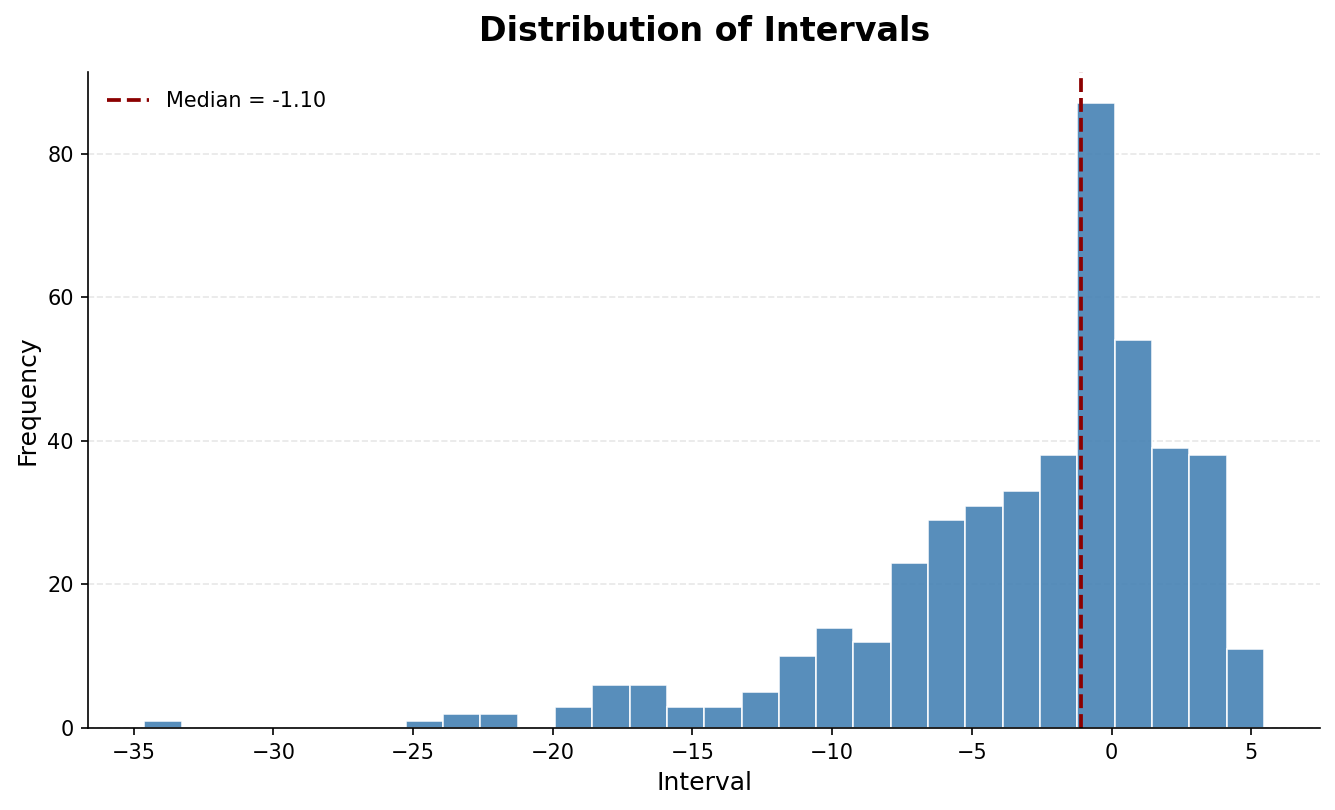

In [19]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare data
intervals = df["interval"].dropna()

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=150)

# Histogram
ax.hist(
    intervals,
    bins=30,
    color="steelblue",
    edgecolor="white",
    linewidth=0.8,
    alpha=0.9
)

# Median reference line
median = intervals.median()
ax.axvline(
    median,
    color="darkred",
    linestyle="--",
    linewidth=1.8,
    label=f"Median = {median:.2f}"
)

# Labels and title
ax.set_title("Distribution of Intervals", fontsize=16, fontweight="bold", pad=15)
ax.set_xlabel("Interval", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)

# Styling
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", labelsize=10)
ax.legend(frameon=False, fontsize=10)

plt.tight_layout()
plt.savefig(
    "interval_distribution.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()
plt.close(fig)

In [20]:
print(df['interval'].describe())

count    451.000000
mean      -2.901260
std        5.732226
min      -34.617385
25%       -5.670089
50%       -1.100616
75%        0.902122
max        5.459274
Name: interval, dtype: float64


In [21]:
print(f"Number of individuals who received a daignosis after WGS biosampling: {len(df[df['interval'] > 0])}")

Number of individuals who received a daignosis after WGS biosampling: 155


In [22]:
WORKSPACEBUCKET = os.environ["WORKSPACE_BUCKET"]

df3 = pd.read_csv(f"{WORKSPACEBUCKET}/data/wgs_qc/analysis_samples_wgs_qc/exome/EUR-like_exome_qc.txt", sep ='\t')

df = df[df['person_id'].isin(df3['IID'])]

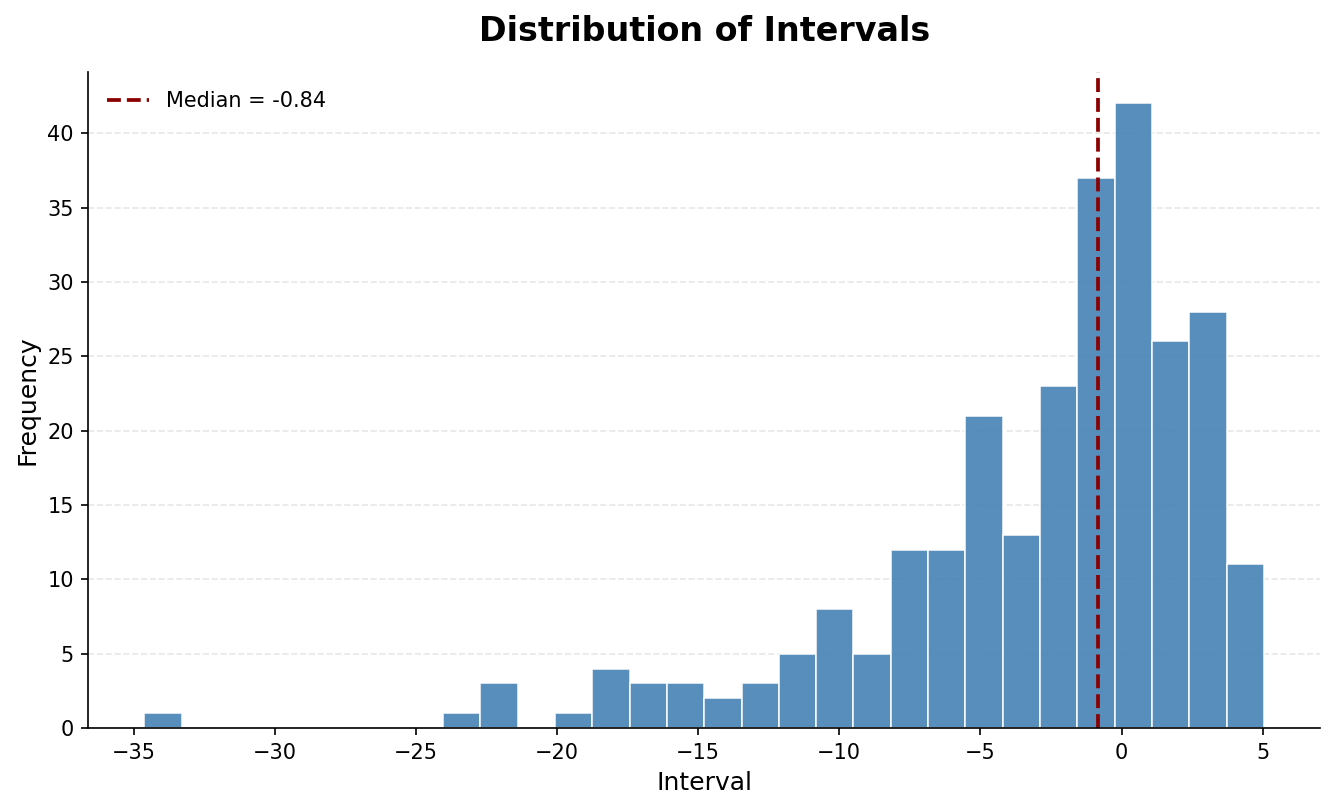

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare data
intervals = df["interval"].dropna()

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=150)

# Histogram
ax.hist(
    intervals,
    bins=30,
    color="steelblue",
    edgecolor="white",
    linewidth=0.8,
    alpha=0.9
)

# Median reference line
median = intervals.median()
ax.axvline(
    median,
    color="darkred",
    linestyle="--",
    linewidth=1.8,
    label=f"Median = {median:.2f}"
)

# Labels and title
ax.set_title("Distribution of Intervals", fontsize=16, fontweight="bold", pad=15)
ax.set_xlabel("Interval", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)

# Styling
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", labelsize=10)
ax.legend(frameon=False, fontsize=10)

plt.tight_layout()
plt.savefig(
    "eur_interval_distribution.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()
plt.close(fig)

In [24]:
print(df['interval'].describe())

count    264.000000
mean      -2.860027
std        6.016233
min      -34.617385
25%       -5.223135
50%       -0.837782
75%        1.065024
max        5.048597
Name: interval, dtype: float64


In [25]:
df = df[df['interval'] > 0]
print(f"Number of individuals who received a daignosis after WGS biosampling: {len(df)}")

Number of individuals who received a daignosis after WGS biosampling: 96


In [26]:
WORKSPACEBUCKET = os.environ["WORKSPACE_BUCKET"]

df.to_csv(f"{WORKSPACEBUCKET}/data/covariates/daignosis_interval.tsv", 
                         sep ='\t',
                         header=False,
                         index=False)

df[['person_id']].to_csv(f"{WORKSPACEBUCKET}/data/covariates/daignosis_interval.samplelist", 
                         sep ='\t',
                         header=False,
                         index=False)

In [27]:
df[['person_id']].to_csv(f"{WORKSPACEBUCKET}/data/covariates/daignosis_interval.samplelist", 
                         sep ='\t',
                         header=False,
                         index=False)

In [28]:
file = pd.read_csv(f"{WORKSPACEBUCKET}/data/saige_phenotype_files/aml_biosample_age_files/EUR_phenotype_file.txt", sep ='\t')

In [29]:
file = file[(file['aml_biosample_age'] == 0) | ((file['aml_biosample_age'] == 1) & (file['person_id'].isin(df['person_id'])))]

In [30]:
print(file['aml_biosample_age'].value_counts()) 

aml_biosample_age
0    169706
1        96
Name: count, dtype: int64


In [31]:
file[['person_id']].to_csv(f"{WORKSPACEBUCKET}/data/saige_phenotype_files/aml_biosample_age_files/samplelist.txt", 
                         sep ='\t',
                         header=False,
                         index=False)